**IMPORTING LIBRARIES**

In [33]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

**LOAD DATASET**

In [34]:
df = pd.read_csv("loan_approval_dataset.csv")

df

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


**DATASET INSPECTION**

In [35]:
#dataset shape
print("Dataset shape:", df.shape)

#columns in dataset
print("\nColumns in Dataset:", df.columns)

Dataset shape: (4269, 13)

Columns in Dataset: Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='str')


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [37]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

**DATA CLEANING**

In [38]:
#renaming columns
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "cibil_score": "credit_score"
})

In [39]:
has_neg_in_col = (df[["income_annum", "loan_amount", "residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value"]] < 0).sum()

print(has_neg_in_col)

income_annum                 0
loan_amount                  0
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64


In [40]:
df = df[df["residential_assets_value"] > 0]

In [41]:
df.info()

<class 'pandas.DataFrame'>
Index: 4196 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4196 non-null   int64
 1   no_of_dependents          4196 non-null   int64
 2   education                 4196 non-null   str  
 3   self_employed             4196 non-null   str  
 4   income_annum              4196 non-null   int64
 5   loan_amount               4196 non-null   int64
 6   loan_term                 4196 non-null   int64
 7   credit_score              4196 non-null   int64
 8   residential_assets_value  4196 non-null   int64
 9   commercial_assets_value   4196 non-null   int64
 10  luxury_assets_value       4196 non-null   int64
 11  bank_asset_value          4196 non-null   int64
 12  loan_status               4196 non-null   str  
dtypes: int64(10), str(3)
memory usage: 556.8 KB


In [42]:
df["education"].unique()

<ArrowStringArray>
[' Graduate', ' Not Graduate']
Length: 2, dtype: str

In [43]:
df["self_employed"].unique()

<ArrowStringArray>
[' No', ' Yes']
Length: 2, dtype: str

In [44]:
df["loan_status"].unique()

<ArrowStringArray>
[' Approved', ' Rejected']
Length: 2, dtype: str

In [45]:
df["education"] = df["education"].str.strip()
df["self_employed"] = df["self_employed"].str.strip()
df["loan_status"] = df["loan_status"].str.strip()

In [46]:
df.to_csv("cleaned_loan_approval_dataset.csv", index=False)

**EDA - DATASET ANALYSIS**

In [47]:
df = pd.read_csv("cleaned_loan_approval_dataset.csv")

df

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,credit_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4191,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4192,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4193,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4194,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [48]:
df["education"].unique()

<ArrowStringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str

In [49]:
#distribution of educated candidates
df["education"].value_counts()

education
Graduate        2107
Not Graduate    2089
Name: count, dtype: int64

In [50]:
df["education"].value_counts(normalize=True)

education
Graduate        0.502145
Not Graduate    0.497855
Name: proportion, dtype: float64

In [51]:
#distibution of self employed candidates
df["self_employed"].value_counts()

self_employed
Yes    2113
No     2083
Name: count, dtype: int64

In [52]:
df["self_employed"].value_counts(normalize=True)

self_employed
Yes    0.503575
No     0.496425
Name: proportion, dtype: float64

In [53]:
#distibution of approved loans
df["loan_status"].value_counts()

loan_status
Approved    2612
Rejected    1584
Name: count, dtype: int64

In [54]:
df["loan_status"].value_counts(normalize=True)

loan_status
Approved    0.622498
Rejected    0.377502
Name: proportion, dtype: float64

In [55]:
#loan term , credit core and no of dependents aggregate 
df[["no_of_dependents", "loan_term", "credit_score"]].agg(['sum', 'mean', 'min', 'max']).map('{:.1f}'.format)

,no_of_dependents,loan_term,credit_score
sum,10478.0,45742.0,2516089.0
mean,2.5,10.9,599.6
min,0.0,2.0,300.0
max,5.0,20.0,900.0


In [56]:
amount_cols = ["income_annum", "loan_amount", "residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value"]
df[amount_cols].agg(['sum', 'mean', 'min', 'max']).map('{:,.2f}'.format)

,income_annum,loan_amount,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
sum,"21,385,800,000.00","63,958,700,000.00","31,903,400,000.00","20,979,200,000.00","63,961,500,000.00","21,043,100,000.00"
mean,"5,096,711.15","15,242,778.84","7,603,288.85","4,999,809.34","15,243,446.14","5,015,038.13"
min,"200,000.00","300,000.00","100,000.00",0.00,"300,000.00",0.00
max,"9,900,000.00","39,500,000.00","29,100,000.00","19,400,000.00","39,200,000.00","14,700,000.00"


**DATA VISUALIZATION**

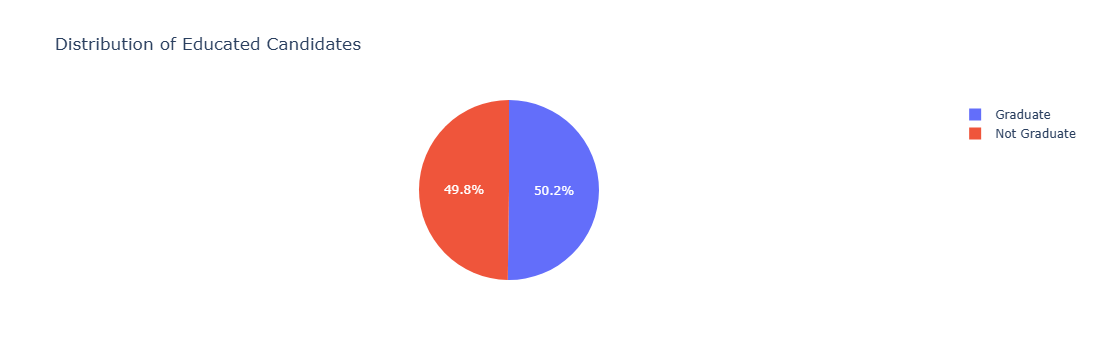

In [57]:
#distibution of educated candidates
fig = px.pie(
    names=df["education"].unique(),
    values=df["education"].value_counts(),
    title="Distribution of Educated Candidates"
)

fig.show()

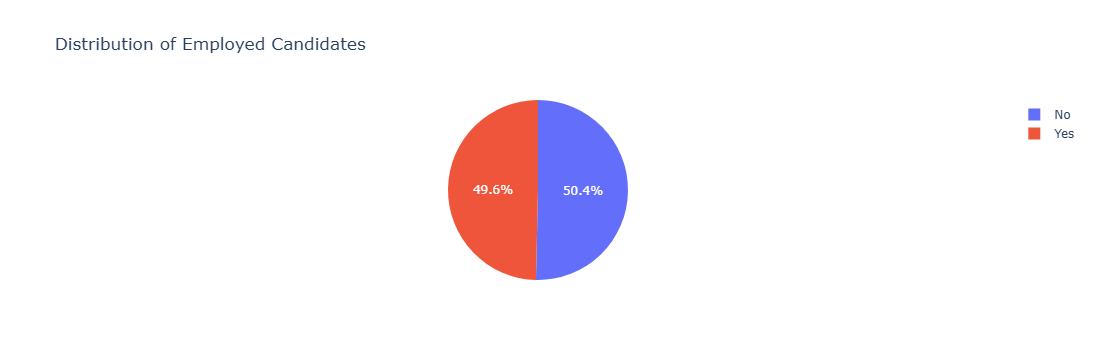

In [58]:
#distibution of employed candidates
fig1 = px.pie(
    names=df["self_employed"].unique(),
    values=df["self_employed"].value_counts(),
    title="Distribution of Employed Candidates"
)

fig1.show()

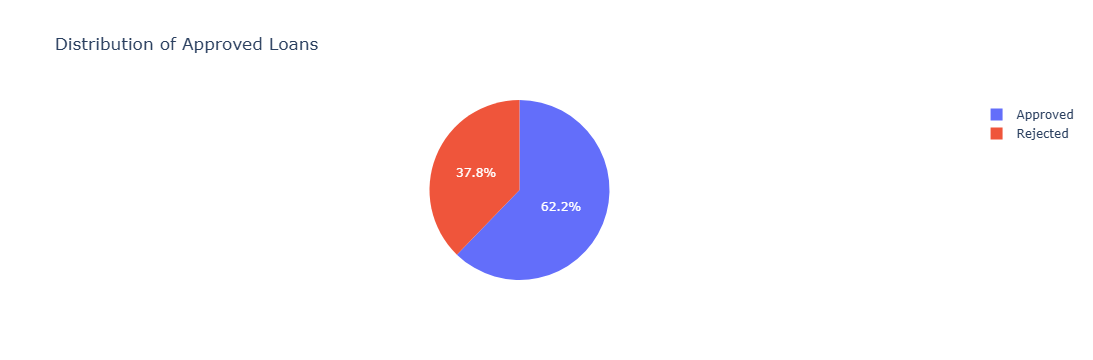

In [59]:
##distibution of approved loan
fig2 = px.pie(
    names=df["loan_status"].unique(),
    values=df["loan_status"].value_counts(),
    title="Distribution of Approved Loans"
)

fig2.show()

In [60]:
df.groupby("education")["credit_score"].sum()

education
Graduate        1260663
Not Graduate    1255426
Name: credit_score, dtype: int64

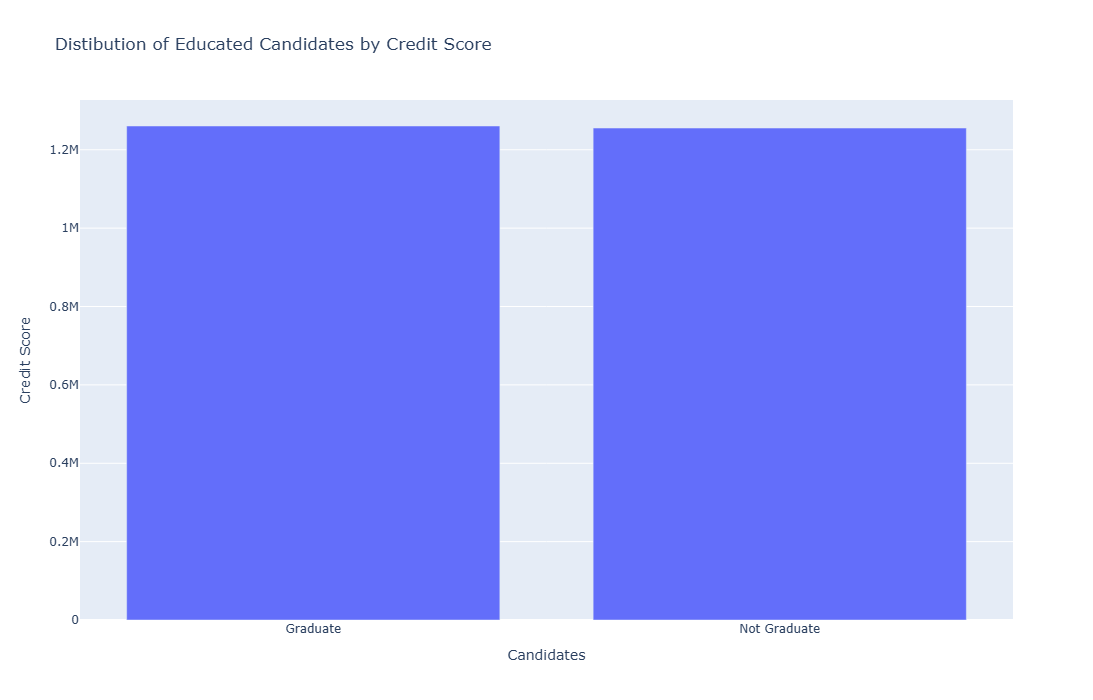

In [61]:
# distibution of educated candidate by credit score
edu_cs = df.groupby("education")["credit_score"].sum()

fig3 = px.bar(
    x = edu_cs.index,
    y = edu_cs.values,
    orientation="v",
    title = "Distibution of Educated Candidates by Credit Score"
)
fig3.update_layout(
    height=700,
    width=500,
    xaxis_title="Candidates",
    yaxis_title= "Credit Score"
)

fig3.show()

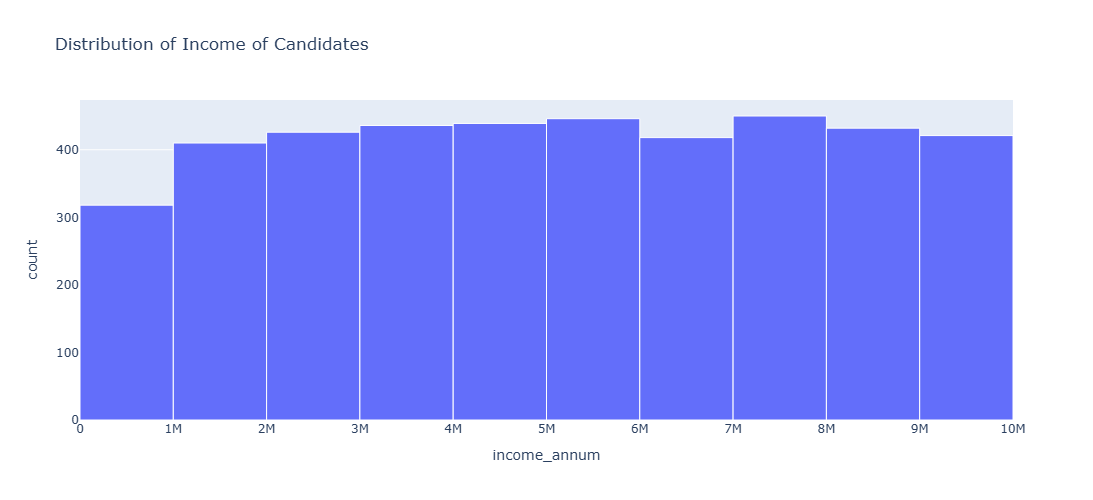

In [62]:
#distribution of income of candidates 
fig7 = px.histogram(
    df,
    x="income_annum",
    nbins=10,
    title="Distribution of Income of Candidates",
    height=500
)
fig7.update_traces(
    marker_line_color="white",
    marker_line_width=1
)
fig7.show()

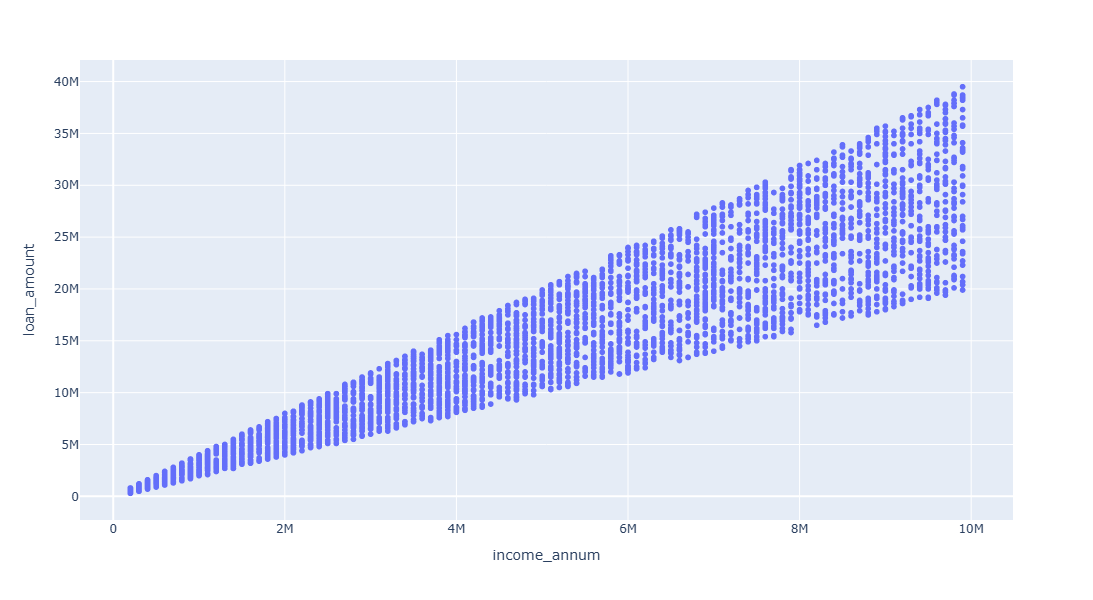

In [63]:
#correlation between income and loan amount
fig0 = px.scatter(
    df, 
    x=df["income_annum"], 
    y=df["loan_amount"],
    height=600
)

fig0.show()

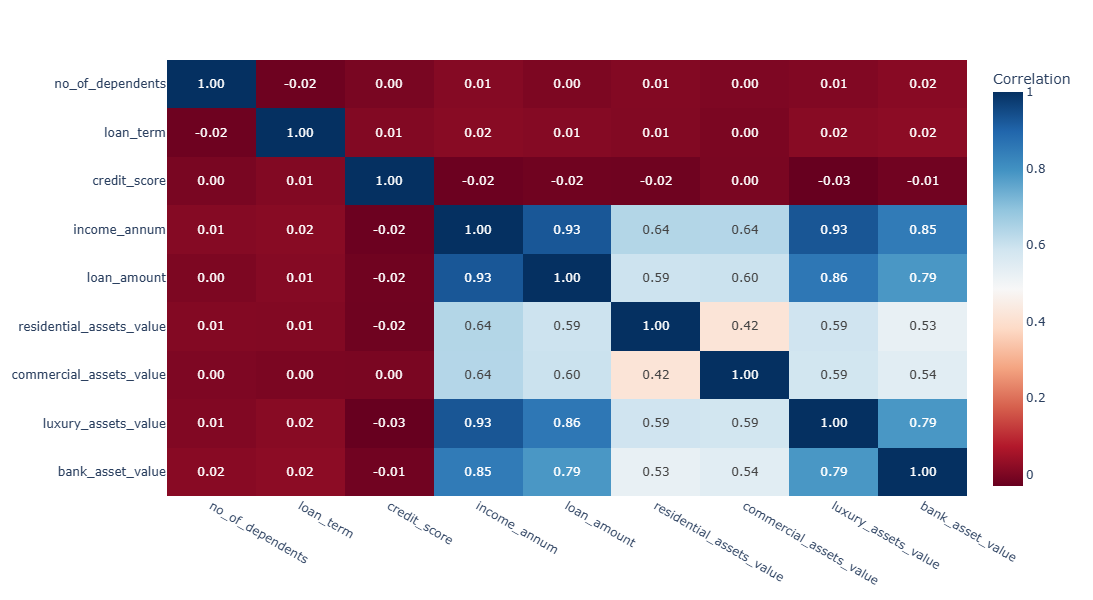

In [64]:
#correlation of num cols
correlation = df[["no_of_dependents", "loan_term", "credit_score", "income_annum", "loan_amount", 
                  "residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value"]].corr()

fig5 = px.imshow(
    correlation,
    text_auto=".2f",
    aspect="auto",
    labels=dict(color="Correlation"),
    color_continuous_scale="RdBu",   
    width=800,                           
    height=600 
)

fig5.show()

#color_continuous_scale="Viridis",     #Changes the color palette (e.g., Viridis, Plasma, RdBu)